In [1]:
import duckdb
import pandas as pd

conn = duckdb.connect('/home/jassiel/Documentos/Labs/repo-principal/lab-10/base_clinica.duckdb')

In [2]:
#Laboratorio 11: Analítica longitudinal
#Actividad 1: de anidado a legible

In [3]:
#Pacientes diabéticos sin prueba de HbA1c
#Original
conn.execute("""
SELECT DISTINCT
    p.Id AS patient_id,
    p.FIRST AS nombre,
    p.LAST AS apellido
FROM patients p
JOIN conditions c ON p.Id = c.PATIENT
WHERE LOWER(c.DESCRIPTION) LIKE '%diabetes%'
  AND NOT EXISTS (
      SELECT 1 
      FROM observations o 
      WHERE o.PATIENT = p.Id 
        AND (LOWER(o.DESCRIPTION) LIKE '%hba1c%' OR LOWER(o.DESCRIPTION) LIKE '%hemoglobin a1c%')
  );
""").df()

,patient_id,nombre,apellido
0,cbe9f5e1-165a-9507-d904-f0fa486ea1c5,Rex53,Murphy561
1,3cb59357-5d6e-bb70-e7d2-2b16ee0357d6,Roberto515,Santiago500
2,aa08743c-9520-8b20-5072-e6b40de9e5aa,Leo278,Walter473
3,3584c5f8-85da-a91a-6e7e-5df8753189e0,Jerry654,Orn563
4,b9c35397-c3a9-bc5b-5dc0-818f5d5f0944,Cherise743,Rodriguez71
5,5b6a19a6-e5fb-44d4-4646-5f9daf911e17,Raymundo71,Tromp100
6,4b2cc620-5e18-f943-cf43-212e55047402,Zachary28,Rolfson709
7,07c8d48c-adae-5755-6f73-5768743fcde4,Fran41,Ledner144
8,5bb9328e-56f5-a14c-7fdf-3911be4be7bc,Benton624,Harris789
9,4358663f-ee77-411b-cf3f-f2f5ee07c18d,Max124,Ziemann98


In [4]:
#CTE
conn.execute("""
WITH pacientes_diabeticos AS (
    SELECT DISTINCT p.Id, p.FIRST, p.LAST
    FROM patients p
    JOIN conditions c ON p.Id = c.PATIENT
    WHERE LOWER(c.DESCRIPTION) LIKE '%diabetes%'
),
mediciones_hba1c AS (
    SELECT DISTINCT PATIENT 
    FROM observations 
    WHERE LOWER(DESCRIPTION) LIKE '%hba1c%' OR LOWER(DESCRIPTION) LIKE '%hemoglobin a1c%'
)
SELECT pd.*
FROM pacientes_diabeticos pd
LEFT JOIN mediciones_hba1c mh ON pd.Id = mh.PATIENT
WHERE mh.PATIENT IS NULL;
""").df()

,Id,FIRST,LAST
0,cbe9f5e1-165a-9507-d904-f0fa486ea1c5,Rex53,Murphy561
1,3cb59357-5d6e-bb70-e7d2-2b16ee0357d6,Roberto515,Santiago500
2,5b6a19a6-e5fb-44d4-4646-5f9daf911e17,Raymundo71,Tromp100
3,4b2cc620-5e18-f943-cf43-212e55047402,Zachary28,Rolfson709
4,3584c5f8-85da-a91a-6e7e-5df8753189e0,Jerry654,Orn563
5,b9c35397-c3a9-bc5b-5dc0-818f5d5f0944,Cherise743,Rodriguez71
6,07c8d48c-adae-5755-6f73-5768743fcde4,Fran41,Ledner144
7,aa08743c-9520-8b20-5072-e6b40de9e5aa,Leo278,Walter473
8,5bb9328e-56f5-a14c-7fdf-3911be4be7bc,Benton624,Harris789
9,4358663f-ee77-411b-cf3f-f2f5ee07c18d,Max124,Ziemann98


Ganamos modularidad y facilidad de depuración: aislar la cohorte y las mediciones en bloques separados permite probar cada CTE individualmente antes del cruce, haciendo que la lógica del anti-join sea evidente a simple vista.

In [5]:
#Promedio de tiempo de seguimiento clínico
#Original
conn.execute("""
SELECT 
    ROUND(AVG(dias_seguimiento), 2) AS promedio_dias_historia
FROM (
    SELECT 
        PATIENT,
        DATEDIFF('day', MIN(START), MAX(START)) AS dias_seguimiento
    FROM encounters
    GROUP BY PATIENT
) sub;
""").df()

,promedio_dias_historia
0,11072.31


In [6]:
#CTE
conn.execute("""
WITH historia_pacientes AS (
    SELECT 
        PATIENT,
        DATEDIFF('day', MIN(START), MAX(START)) AS dias_seguimiento
    FROM encounters
    GROUP BY PATIENT
)
SELECT 
    ROUND(AVG(dias_seguimiento), 2) AS promedio_dias_historia
FROM historia_pacientes;
""").df()

,promedio_dias_historia
0,11072.31


Pasamos de leer el código de adentro hacia afuera a una lectura lineal de arriba hacia abajo. En este caso particular de una sola anidación la ganancia de rendimiento es nula, pero prepara el terreno visual para encadenar más pasos sin colapsar la legibilidad.

In [7]:
#Actividad 2: depurar por partes
#Bloque 1: Inspeccionar la primera CTE aislada
print("Bloque 1: pacientes_diabeticos")
df_cte1 = conn.execute("""
    SELECT DISTINCT p.Id, p.FIRST, p.LAST
    FROM patients p
    JOIN conditions c ON p.Id = c.PATIENT
    WHERE LOWER(c.DESCRIPTION) LIKE '%diabetes%'
""").df()
print(f"Filas devueltas: {len(df_cte1)}")
display(df_cte1.head(3))

#Bloque 2: inspeccionar la segunda CTE aislada
print("\nBloque 2: mediciones_hba1c")
df_cte2 = conn.execute("""
    SELECT DISTINCT PATIENT 
    FROM observations 
    WHERE LOWER(DESCRIPTION) LIKE '%hba1c%' OR LOWER(DESCRIPTION) LIKE '%hemoglobin a1c%'
""").df()
print(f"Filas devueltas: {len(df_cte2)}")
display(df_cte2.head(3))

#Bloque 3: el cruce final completo
print("\nBloque 3: Resultado final (anti-join)")
df_final = conn.execute("""
    WITH pacientes_diabeticos AS (
        SELECT DISTINCT p.Id, p.FIRST, p.LAST
        FROM patients p
        JOIN conditions c ON p.Id = c.PATIENT
        WHERE LOWER(c.DESCRIPTION) LIKE '%diabetes%'
    ),
    mediciones_hba1c AS (
        SELECT DISTINCT PATIENT 
        FROM observations 
        WHERE LOWER(DESCRIPTION) LIKE '%hba1c%' OR LOWER(DESCRIPTION) LIKE '%hemoglobin a1c%'
    )
    SELECT pd.*
    FROM pacientes_diabeticos pd
    LEFT JOIN mediciones_hba1c mh ON pd.Id = mh.PATIENT
    WHERE mh.PATIENT IS NULL;
""").df()
print(f"Filas devueltas: {len(df_final)}")
display(df_final.head(3))

Bloque 1: pacientes_diabeticos
Filas devueltas: 227


,Id,FIRST,LAST
0,bf28bf65-0434-1696-16d1-bac3d849501c,Emily542,Rice937
1,d31111c6-1d20-6479-d22f-4ed413bf0217,Debra128,Zieme486
2,65ae0894-ec19-982d-fdaf-de1a7a535f73,Raquel318,Carmona375



Bloque 2: mediciones_hba1c
Filas devueltas: 233


,PATIENT
0,c9ec4185-c14f-2167-035d-d7757b806424
1,1da442f7-f063-4ac9-d69a-3c0d4020d388
2,32d77305-8ed6-dc9f-9d9b-fdcef02809dc



Bloque 3: Resultado final (anti-join)
Filas devueltas: 10


,Id,FIRST,LAST
0,07c8d48c-adae-5755-6f73-5768743fcde4,Fran41,Ledner144
1,cbe9f5e1-165a-9507-d904-f0fa486ea1c5,Rex53,Murphy561
2,aa08743c-9520-8b20-5072-e6b40de9e5aa,Leo278,Walter473


Resultados de la inspección:
Bloque 1 (pacientes_diabeticos): 227 filas devueltas.
Bloque 2 (mediciones_hba1c): 233 filas devueltas.
Bloque 3 (cruce final): 10 filas devueltas (los pacientes que están en el Bloque 1 pero no en el Bloque 2).

¿Qué ventaja práctica se demostró?
Al utilizar CTEs, el código actúa como un pipeline de transformación de datos. Si el resultado final de 10 pacientes me pareciera extraño, puedo simplemente ejecutar `SELECT *` del primer o segundo bloque de forma independiente para auditar si el error viene de un filtro mal escrito en los diagnósticos o en los laboratorios. En una consulta anidada tradicional, esto es imposible sin desarmar y reescribir todo el bloque de código desde cero.

In [8]:
#Actividad 3: primera y última visita por paciente
print("1. Solución con GROUP BY")
df_groupby = conn.execute("""
    SELECT 
        PATIENT,
        MIN(START) AS primera_visita,
        MAX(START) AS ultima_visita,
        COUNT(Id) AS total_visitas
    FROM encounters
    GROUP BY PATIENT
    ORDER BY PATIENT;
""").df()
display(df_groupby.head(5))


print("\n2. Solución con Window Functions")
df_windows = conn.execute("""
    SELECT DISTINCT
        PATIENT,
        FIRST_VALUE(START) OVER (PARTITION BY PATIENT ORDER BY START) AS primera_visita,
        -- LA TRAMPA: Si no ponemos la ventana completa, LAST_VALUE devuelve la fila actual
        LAST_VALUE(START) OVER (
            PARTITION BY PATIENT 
            ORDER BY START 
            RANGE BETWEEN UNBOUNDED PRECEDING AND UNBOUNDED FOLLOWING
        ) AS ultima_visita,
        COUNT(Id) OVER (PARTITION BY PATIENT) AS total_visitas
    FROM encounters
    ORDER BY PATIENT;
""").df()
display(df_windows.head(5))

#Verificación de que dan exactamente lo mismo
son_iguales = df_groupby.equals(df_windows)
print(f"\n¿Los resultados son exactamente iguales? {son_iguales}")

1. Solución con GROUP BY


,PATIENT,primera_visita,ultima_visita,total_visitas
0,00dbff13-8767-26c9-5315-d938617e3e07,2016-05-15 21:30:33,2026-06-07 21:30:33,36
1,012acae3-d0f3-3493-b3cb-bb430437d0f8,2019-11-30 07:49:09,2025-11-15 07:49:09,18
2,0276003c-ce0c-a4cb-b2ed-5443d03cdf46,1997-02-20 03:02:44,2025-01-30 03:02:44,16
3,032e8472-885d-73e5-f9cf-e9505c85e11e,1929-08-09 09:09:30,2005-08-03 08:25:30,111
4,03623a36-9e65-0980-164f-ffa841234b12,1945-10-04 07:01:26,2026-01-11 12:01:26,48



2. Solución con Window Functions


,PATIENT,primera_visita,ultima_visita,total_visitas
0,00dbff13-8767-26c9-5315-d938617e3e07,2016-05-15 21:30:33,2026-06-07 21:30:33,36
1,012acae3-d0f3-3493-b3cb-bb430437d0f8,2019-11-30 07:49:09,2025-11-15 07:49:09,18
2,0276003c-ce0c-a4cb-b2ed-5443d03cdf46,1997-02-20 03:02:44,2025-01-30 03:02:44,16
3,032e8472-885d-73e5-f9cf-e9505c85e11e,1929-08-09 09:09:30,2005-08-03 08:25:30,111
4,03623a36-9e65-0980-164f-ffa841234b12,1945-10-04 07:01:26,2026-01-11 12:01:26,48



¿Los resultados son exactamente iguales? True


La trampa de LAST_VALUE:
El frame (ventana) por defecto en SQL cuando usas `ORDER BY` dentro de la cláusula `OVER()` es `RANGE BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW`. Es decir, la ventana termina en la fila actual. Si no se modifica, `LAST_VALUE` simplemente te devolverá la fecha de la fila que está evaluando en ese instante, no la última fecha de todo el paciente. Para corregirlo, fue obligatorio extender la ventana explícitamente con `RANGE BETWEEN UNBOUNDED PRECEDING AND UNBOUNDED FOLLOWING`.

¿Qué enfoque prefiero y por qué?
Prefiero el GROUP BY, porque colapsa naturalmente las filas, lo cual es exactamente el objetivo: una fila por paciente. Usar funciones de ventana aquí es forzar la herramienta: tuvimos que calcular los valores agregados repetidamente fila por fila para luego usar un `DISTINCT` artificial que eliminara los duplicados. Las Window Functions brillan cuando necesitamos mantener el detalle original de las filas, pero para una simple agregación total, GROUP BY es más limpio, rápido y legible.

In [9]:
#Actividad 4: días entre visitas consecutivas

#Calcular días entre visitas usando LAG
print("Días entre visitas")
df_lag = conn.execute("""
    WITH visitas_con_lag AS (
        SELECT 
            PATIENT,
            START AS fecha_visita,
            LAG(START) OVER (PARTITION BY PATIENT ORDER BY START) AS fecha_anterior,
            DATEDIFF('day', 
                     LAG(START) OVER (PARTITION BY PATIENT ORDER BY START), 
                     START) AS dias_transcurridos
        FROM encounters
    )
    SELECT * 
    FROM visitas_con_lag
    ORDER BY PATIENT, fecha_visita;
""").df()

display(df_lag.head(10))


#Calcular la mediana
print("\nMediana global de días entre visitas")
df_mediana = conn.execute("""
    WITH visitas_con_lag AS (
        SELECT 
            DATEDIFF('day', 
                     LAG(START) OVER (PARTITION BY PATIENT ORDER BY START), 
                     START) AS dias_transcurridos
        FROM encounters
    )
    SELECT MEDIAN(dias_transcurridos) AS mediana_dias
    FROM visitas_con_lag;
""").df()

display(df_mediana)

Días entre visitas


,PATIENT,fecha_visita,fecha_anterior,dias_transcurridos
0,00dbff13-8767-26c9-5315-d938617e3e07,2016-05-15 21:30:33,NaT,<NA>
1,00dbff13-8767-26c9-5315-d938617e3e07,2016-11-13 21:30:33,2016-05-15 21:30:33,182
2,00dbff13-8767-26c9-5315-d938617e3e07,2017-01-26 19:30:33,2016-11-13 21:30:33,74
3,00dbff13-8767-26c9-5315-d938617e3e07,2017-02-12 21:30:33,2017-01-26 19:30:33,17
4,00dbff13-8767-26c9-5315-d938617e3e07,2017-02-19 21:30:33,2017-02-12 21:30:33,7
5,00dbff13-8767-26c9-5315-d938617e3e07,2017-05-14 21:30:33,2017-02-19 21:30:33,84
6,00dbff13-8767-26c9-5315-d938617e3e07,2017-11-12 21:30:33,2017-05-14 21:30:33,182
7,00dbff13-8767-26c9-5315-d938617e3e07,2018-05-13 21:30:33,2017-11-12 21:30:33,182
8,00dbff13-8767-26c9-5315-d938617e3e07,2018-11-11 21:30:33,2018-05-13 21:30:33,182
9,00dbff13-8767-26c9-5315-d938617e3e07,2019-05-12 21:30:33,2018-11-11 21:30:33,182



Mediana global de días entre visitas


,mediana_dias
0,20.0


**1. ¿Cuál es la mediana de días entre visitas?**
* La mediana global de la cohorte es de 20.0 días.

**2. ¿Por qué la primera visita de cada paciente da NULL? ¿Está bien?**
* Da `NULL` porque la función `LAG()` busca el valor de la fila inmediatamente anterior dentro de la partición del paciente. Al ser el primer registro cronológico de su historia clínica, no existe un evento previo contra el cual calcular una diferencia, por lo que representa la ausencia de un intervalo, no un intervalo de valor cero.

**3. ¿Qué harías con esos NULL al calcular la mediana?**
* Deben ser excluidos del cálculo. Si cometiéramos el error de imputarlos como 0 estaríamos alterando severamente la distribución, asumiendo falsamente que el paciente tuvo visitas simultáneas. Funciones de agregación en motores SQL como DuckDB (`MEDIAN`, `AVG`) ignoran automáticamente los valores nulos por diseño, por lo que el cálculo de 20.0 días es exacto y no se ve sesgado.

In [10]:
#Actividad 5: Readmisión a 30 días

print("Cálculo de Readmisiones a 30 días")
df_readmisiones = conn.execute("""
    WITH ingresos AS (
        -- 1. Filtramos solo los ingresos hospitalarios (inpatient)
        SELECT 
            PATIENT,
            START AS fecha_ingreso,
            STOP AS fecha_alta
        FROM encounters
        WHERE LOWER(ENCOUNTERCLASS) = 'inpatient'
    ),
    altas_con_futuro AS (
        -- 2. Con LEAD, buscamos la fecha del SIGUIENTE ingreso del mismo paciente
        SELECT 
            PATIENT,
            fecha_ingreso,
            fecha_alta,
            LEAD(fecha_ingreso) OVER (PARTITION BY PATIENT ORDER BY fecha_ingreso) AS siguiente_ingreso
        FROM ingresos
    ),
    evaluacion_30d AS (
        -- 3. Calculamos la diferencia en días y etiquetamos si es <= 30
        SELECT 
            *,
            DATEDIFF('day', fecha_alta, siguiente_ingreso) AS dias_para_reingreso,
            CASE 
                WHEN DATEDIFF('day', fecha_alta, siguiente_ingreso) BETWEEN 0 AND 30 THEN 1 
                ELSE 0 
            END AS readmision_30d
        FROM altas_con_futuro
    )
    -- 4. Agrupamos los totales para sacar la tasa
    SELECT 
        COUNT(*) AS altas_elegibles,
        SUM(readmision_30d) AS total_readmisiones,
        ROUND((SUM(readmision_30d) * 100.0) / COUNT(*), 2) AS tasa_readmision_pct
    FROM evaluacion_30d;
""").df()

display(df_readmisiones)

Cálculo de Readmisiones a 30 días


,altas_elegibles,total_readmisiones,tasa_readmision_pct
0,499,75.0,15.03


**Resultados:**
* **Altas elegibles (inpatient): 499
* **Total de readmisiones a 30 días: 75
* **Tasa de readmisión: 15.03%

1. **¿Qué eventos califican?** Se filtró estrictamente por `ENCOUNTERCLASS = 'inpatient'`. Las visitas ambulatorias o de urgencia que no terminaron en hospitalización no cuentan ni como alta índice ni como readmisión.
2. **¿Todas o solo la primera?** Se evaluaron todas las readmisiones independientes. Si un paciente tiene múltiples ingresos a lo largo de su vida, cada alta se trata como un evento elegible ("alta índice") que puede desencadenar una nueva readmisión. Esto evita el sesgo de supervivencia en pacientes crónicos.
3. **¿El día 30 entra o no?** Sí, el límite es inclusivo (`BETWEEN 0 AND 30`). Si un paciente es dado de alta el 1 de enero y reingresa el 31 de enero, cuenta matemáticamente como un evento a los 30 días exactos y se marca como readmisión. Se incluye el 0 para capturar traslados o reingresos en el mismo día.


Muestra de tabla (gap 30 días)


,PATIENT,episode_id,episode_start,episode_end,duration_days
0,03ef3aa8-c85f-7260-e2ef-276c6efa0564,1.0,2002-08-18 04:18:51,2026-11-13,8853
1,06213c84-2185-5316-fc77-92cfa1fdeb7a,1.0,2012-03-04 17:35:59,2026-11-13,5367
2,086f09ee-9cf7-e305-119c-28d8b3051433,1.0,2000-08-19 01:33:08,2026-11-13,9582
3,0aaf2d72-6de9-06c3-4ca5-10bc24a4caa0,1.0,1997-04-15 04:55:29,2026-11-13,10804
4,0b31a973-2748-30ed-b74f-a293d0662cb7,1.0,2007-10-14 12:17:07,2026-11-13,6970


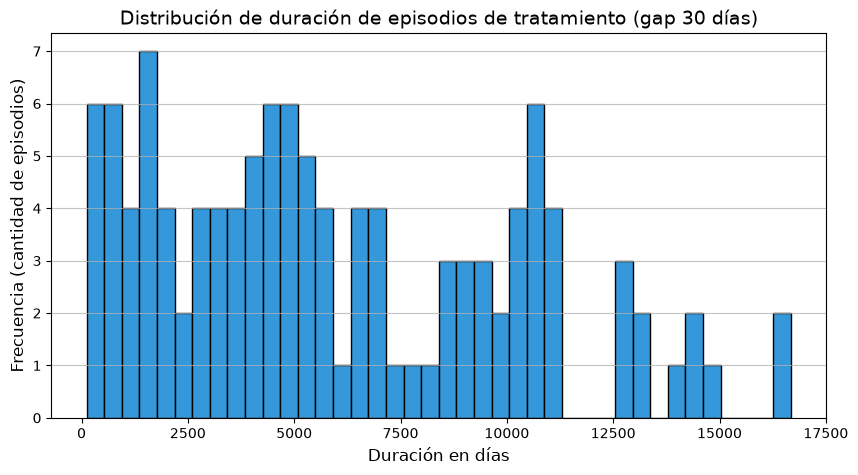

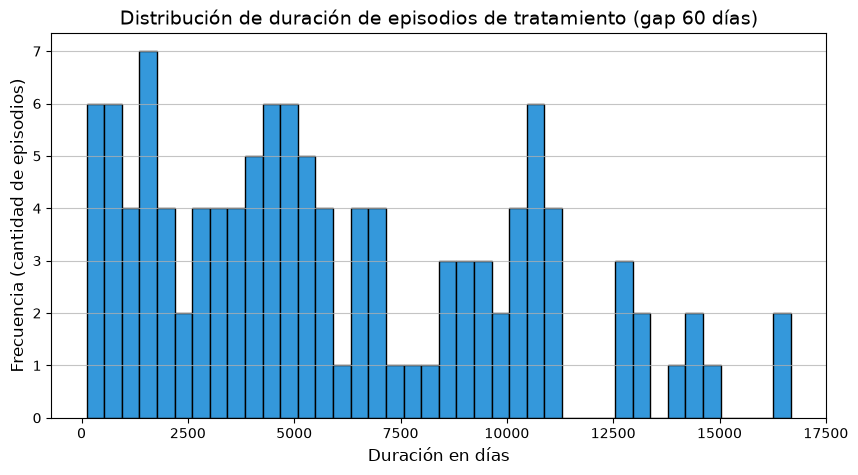

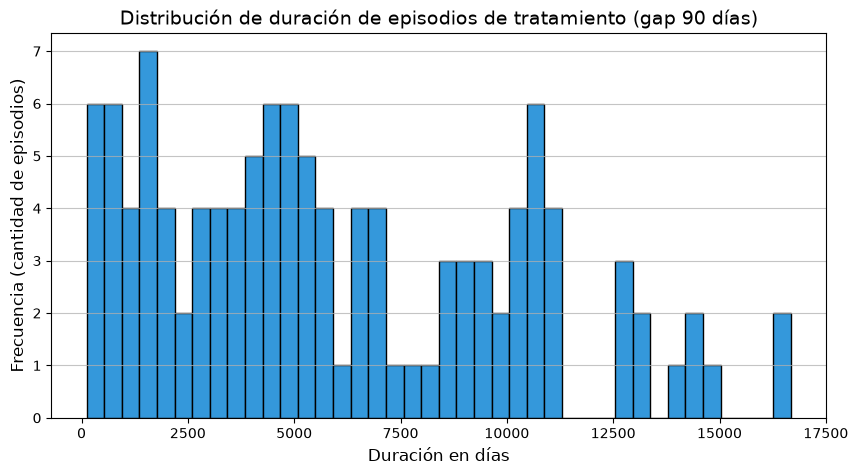

Comparativa de episodios (simvastatina)
Total episodios (gap 30 días): 115
Total episodios (gap 60 días): 115
Total episodios (gap 90 días): 115


In [11]:
#Actividad 6: episodios de tratamiento (gaps and islands)
import matplotlib.pyplot as plt

def calcular_episodios(gap_dias, medicamento='%simvastatin%'):
    query = f"""
        WITH med_data AS (
            -- 1. Filtramos el medicamento y manejamos tratamientos activos (STOP nulo)
            SELECT 
                PATIENT, 
                START, 
                COALESCE(STOP, CURRENT_DATE) AS STOP
            FROM medications
            WHERE LOWER(DESCRIPTION) LIKE '{medicamento}'
        ),
        lagged AS (
            -- 2. Obtenemos la fecha de fin de la dispensación anterior
            SELECT 
                PATIENT, 
                START, 
                STOP,
                LAG(STOP) OVER (PARTITION BY PATIENT ORDER BY START) AS prev_stop
            FROM med_data
        ),
        islands AS (
            -- 3. Identificamos si es un nuevo episodio (1) o continuación del mismo (0)
            SELECT 
                PATIENT, 
                START, 
                STOP,
                CASE 
                    WHEN prev_stop IS NULL 
                         OR DATEDIFF('day', prev_stop, START) > {gap_dias} THEN 1 
                    ELSE 0 
                END AS is_new_episode
            FROM lagged
        ),
        episodes_grouped AS (
            -- 4. Suma acumulativa para crear un ID único por episodio (la isla)
            SELECT 
                PATIENT, 
                START, 
                STOP,
                SUM(is_new_episode) OVER (PARTITION BY PATIENT ORDER BY START) AS episode_id
            FROM islands
        )
        -- 5. Agrupamos por paciente e isla para obtener el periodo completo
        SELECT 
            PATIENT,
            episode_id,
            MIN(START) AS episode_start,
            MAX(STOP) AS episode_end,
            DATEDIFF('day', MIN(START), MAX(STOP)) AS duration_days
        FROM episodes_grouped
        GROUP BY PATIENT, episode_id
        ORDER BY PATIENT, episode_start;
    """
    return conn.execute(query).df()

#Calcular para 30 días
df_30 = calcular_episodios(30)

#Tabla de resultados para 30 días
print("\nMuestra de tabla (gap 30 días)")
display(df_30.head())

#Generar el Histograma para el gap de 30 días
plt.figure(figsize=(10, 5))
plt.hist(df_30['duration_days'], bins=40, color='#3498db', edgecolor='black')
plt.title('Distribución de duración de episodios de tratamiento (gap 30 días)', fontsize=14)
plt.xlabel('Duración en días', fontsize=12)
plt.ylabel('Frecuencia (cantidad de episodios)', fontsize=12)
plt.grid(axis='y', alpha=0.75)
plt.show()

#Calcular para 60 días
df_60 = calcular_episodios(60)

#Generar el Histograma para el gap de 60 días
plt.figure(figsize=(10, 5))
plt.hist(df_60['duration_days'], bins=40, color='#3498db', edgecolor='black')
plt.title('Distribución de duración de episodios de tratamiento (gap 60 días)', fontsize=14)
plt.xlabel('Duración en días', fontsize=12)
plt.ylabel('Frecuencia (cantidad de episodios)', fontsize=12)
plt.grid(axis='y', alpha=0.75)
plt.show()

#Calcular para 90 días
df_90 = calcular_episodios(90)

#Generar el Histograma para el gap de 90 días
plt.figure(figsize=(10, 5))
plt.hist(df_90['duration_days'], bins=40, color='#3498db', edgecolor='black')
plt.title('Distribución de duración de episodios de tratamiento (gap 90 días)', fontsize=14)
plt.xlabel('Duración en días', fontsize=12)
plt.ylabel('Frecuencia (cantidad de episodios)', fontsize=12)
plt.grid(axis='y', alpha=0.75)
plt.show()

print("Comparativa de episodios (simvastatina)")
print(f"Total episodios (gap 30 días): {len(df_30)}")
print(f"Total episodios (gap 60 días): {len(df_60)}")
print(f"Total episodios (gap 90 días): {len(df_90)}")


**Medicamento seleccionado:** Simvastatina (LOWER(DESCRIPTION) LIKE '%simvastatin%').

**Comparativa de Gaps de persistencia:**
* Episodios con gap de 30 días: 115
* Episodios con gap de 60 días: 115
* Episodios con gap de 90 días: 115

**Implicaciones clínicas y analíticas:**
El cambio de gap no modificó la cantidad de episodios descubiertos. Al observar las duraciones (muchas superando los 10,000 días), comprobamos que Synthea registra la medicación crónica como una única receta ininterrumpida (una fila con `START` y sin `STOP` explícito), en lugar de generar registros de dispensación mensual (refills). 

Dado que cada paciente solo tiene un registro de simvastatina, el algoritmo de gaps and islands no tiene eventos que unificar, en este modelo sintético comprobamos una adherencia simulada perfecta del 100%. Este principio es fundamental para comprender cómo poblaremos la tabla `DRUG_ERA` en OMOP.

In [12]:
#Actividad 7: deduplicar con ROW_NUMBER

#Conteo antes de deduplicar (todas las observaciones)
print("Conteo antes de deduplicar")
df_antes = conn.execute("""
    SELECT COUNT(*) AS total_observaciones 
    FROM observations;
""").df()
display(df_antes)

#Conteo y consulta después de deduplicar
print("\nConteo después de deduplicar (solo la más reciente por paciente y analito)")
df_despues = conn.execute("""
    WITH observaciones_rankeadas AS (
        SELECT 
            PATIENT,
            DATE,
            DESCRIPTION,
            VALUE,
            UNITS,
            ROW_NUMBER() OVER (
                PARTITION BY PATIENT, DESCRIPTION 
                ORDER BY DATE DESC
            ) AS rn
        FROM observations
    )
    SELECT COUNT(*) AS total_deduplicadas
    FROM observaciones_rankeadas
    WHERE rn = 1;
""").df()
display(df_despues)

#Muestra de los datos limpios
print("\nMuestra de observaciones deduplicadas")
df_muestra = conn.execute("""
    WITH observaciones_rankeadas AS (
        SELECT 
            PATIENT,
            DATE,
            DESCRIPTION,
            VALUE,
            UNITS,
            ROW_NUMBER() OVER (
                PARTITION BY PATIENT, DESCRIPTION 
                ORDER BY DATE DESC
            ) AS rn
        FROM observations
    )
    SELECT PATIENT, DATE, DESCRIPTION, VALUE, UNITS
    FROM observaciones_rankeadas
    WHERE rn = 1
    ORDER BY PATIENT, DATE DESC
    LIMIT 5;
""").df()
display(df_muestra)

Conteo antes de deduplicar


,total_observaciones
0,409803



Conteo después de deduplicar (solo la más reciente por paciente y analito)


,total_deduplicadas
0,33965



Muestra de observaciones deduplicadas


,PATIENT,DATE,DESCRIPTION,VALUE,UNITS
0,00dbff13-8767-26c9-5315-d938617e3e07,2026-05-24 21:30:33,Body Weight,38.1,kg
1,00dbff13-8767-26c9-5315-d938617e3e07,2026-05-24 21:30:33,Body Height,153.1,cm
2,00dbff13-8767-26c9-5315-d938617e3e07,2026-05-24 21:30:33,Body mass index (BMI) [Ratio],16.3,kg/m2
3,00dbff13-8767-26c9-5315-d938617e3e07,2026-05-24 21:30:33,Pain severity - 0-10 verbal numeric rating [Sc...,0.0,{score}
4,00dbff13-8767-26c9-5315-d938617e3e07,2026-05-24 21:30:33,Body mass index (BMI) [Percentile] Per age and...,35.1,%


#Actividad 7: deduplicar con ROW_NUMBER

**Resultados de la deduplicación:**
* **Conteo antes (todas las observaciones): 409,803
* **Conteo después (solo la más reciente): 33,965

El filtro `rn = 1` no puede ir en el WHERE de la misma consulta porque en el orden lógico de ejecución de SQL, la cláusula `WHERE` se evalúa antes que las funciones de ventana (`OVER`), por lo tanto, la columna `rn` aún no existe en el momento de filtrar, obligándonos a empaquetar el cálculo en una CTE o subconsulta previa.

In [13]:
#Actividad 8: media móvil y frames

print("Media acumulada vs media móvil de 3 mediciones")
df_frames = conn.execute("""
    WITH paciente_ejemplo AS (
        -- 1. Buscamos automáticamente un paciente con al menos 5 mediciones
        SELECT PATIENT
        FROM observations
        WHERE DESCRIPTION = 'Body Weight'
        GROUP BY PATIENT
        HAVING COUNT(*) >= 5  -- <-- AQUÍ ESTÁ LA CORRECCIÓN
        LIMIT 1
    )
    -- 2. Calculamos las métricas para ese paciente específico
    SELECT 
        DATE::DATE AS fecha_medicion,
        VALUE::FLOAT AS peso_actual,
        
        -- Acumulado (Frame por defecto: desde el inicio de los tiempos hasta hoy)
        ROUND(AVG(VALUE::FLOAT) OVER (
            PARTITION BY PATIENT 
            ORDER BY DATE
        ), 2) AS media_acumulada,
        
        -- Media móvil de 3 (Frame declarado: 2 anteriores + la actual)
        ROUND(AVG(VALUE::FLOAT) OVER (
            PARTITION BY PATIENT 
            ORDER BY DATE 
            ROWS BETWEEN 2 PRECEDING AND CURRENT ROW
        ), 2) AS media_movil_3
        
    FROM observations
    WHERE DESCRIPTION = 'Body Weight' 
      AND PATIENT = (SELECT PATIENT FROM paciente_ejemplo)
    ORDER BY fecha_medicion;
""").df()

display(df_frames)

Media acumulada vs media móvil de 3 mediciones


,fecha_medicion,peso_actual,media_acumulada,media_movil_3
0,2016-12-17,17.100000,17.10,17.10
1,2017-12-23,19.000000,18.05,18.05
2,2018-09-15,21.299999,19.13,19.13
3,2018-09-22,21.299999,19.67,20.53
4,2018-12-29,22.000000,20.14,21.53
5,2020-01-04,24.299999,20.83,22.53
6,2021-01-09,26.500000,21.64,24.27
7,2022-01-15,29.200001,22.59,26.67
8,2023-01-21,31.600000,23.59,29.10
9,2024-01-27,36.299999,24.86,32.37


Se extrajo la historia de peso corporal (`Body Weight`) de un paciente. Al comparar las funciones de agregación, observamos que en las primeras 3 mediciones ambas columnas son idénticas, pero a partir de la cuarta comienzan a cambiar. Al final del registro, el paciente pesa ~41.6 kg; la media móvil marca ~39.9 kg (muy cerca de su realidad actual), pero la media acumulada marca apenas ~28.3 kg porque sigue promediando los pesos de su infancia.

Difieren  por el límite inferior de la ventana (*frame*):
* **El acumulado (por defecto):** SQL aplica implícitamente `RANGE BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW`. Esto significa que la media se calcula usando toda la historia clínica del paciente hasta esa fecha. Es un promedio histórico con mucha inercia que reacciona lento a los cambios.
* **La media móvil (declarado):** Al forzar `ROWS BETWEEN 2 PRECEDING AND CURRENT ROW`, limitamos la memoria de la ventana. Solo se promedian la medición actual y las dos visitas inmediatamente anteriores. Esto genera un indicador mucho más sensible a las tendencias recientes.

In [14]:
#Actividad 9: el valor más cercano a una fecha índice

print("Valor de HbA1c más cercano al diagnóstico de Diabetes (ventana: -90 a 0 días)")
df_closest_lab = conn.execute("""
    WITH fecha_indice AS (
        -- 1. Definimos la fecha índice: Primer diagnóstico de diabetes por paciente
        SELECT 
            PATIENT,
            MIN(START) AS fecha_diagnostico
        FROM conditions
        WHERE LOWER(DESCRIPTION) LIKE '%diabetes%'
        GROUP BY PATIENT
    ),
    mediciones_ventana AS (
        -- 2. Buscamos mediciones de HbA1c
        SELECT 
            fi.PATIENT,
            fi.fecha_diagnostico,
            o.DATE AS fecha_laboratorio,
            o.DESCRIPTION AS analito,
            o.VALUE AS resultado,
            -- DATEDIFF: Fecha mayor (diagnóstico) menos fecha menor (laboratorio)
            DATEDIFF('day', o.DATE, fi.fecha_diagnostico) AS dias_antes_diagnostico
        FROM fecha_indice fi
        JOIN observations o ON fi.PATIENT = o.PATIENT
        WHERE (LOWER(o.DESCRIPTION) LIKE '%hba1c%' OR LOWER(o.DESCRIPTION) LIKE '%hemoglobin a1c%')
          -- DECISIÓN OBLIGATORIA: Filtramos estrictamente entre 0 y 90 días antes del diagnóstico.
          -- Descartamos cualquier valor negativo (laboratorios posteriores a la fecha índice).
          AND DATEDIFF('day', o.DATE, fi.fecha_diagnostico) BETWEEN 0 AND 90
    ),
    lab_mas_cercano AS (
        -- 3. Ordenamos para quedarnos con el más cercano (menor diferencia absoluta de días)
        SELECT 
            *,
            ROW_NUMBER() OVER (
                PARTITION BY PATIENT 
                ORDER BY dias_antes_diagnostico ASC
            ) AS rn
        FROM mediciones_ventana
    )
    -- 4. Filtramos la medición número 1 (la más cercana)
    SELECT 
        PATIENT,
        fecha_diagnostico,
        fecha_laboratorio,
        analito,
        resultado,
        dias_antes_diagnostico
    FROM lab_mas_cercano
    WHERE rn = 1
    ORDER BY dias_antes_diagnostico ASC;
""").df()

display(df_closest_lab.head(10))
print(f"\nTotal de pacientes con un HbA1c válido en la ventana previa: {len(df_closest_lab)}")

Valor de HbA1c más cercano al diagnóstico de Diabetes (ventana: -90 a 0 días)


,PATIENT,fecha_diagnostico,fecha_laboratorio,analito,resultado,dias_antes_diagnostico
0,9dec9095-69a7-d8c5-4881-442439fa36f2,2021-06-19,2021-06-19 23:02:13,Hemoglobin A1c/Hemoglobin.total in Blood,6.3,0
1,d51df77b-01c2-7c76-ecd0-db03d8c9bcec,2021-07-20,2021-07-20 11:53:32,Hemoglobin A1c/Hemoglobin.total in Blood,6.3,0
2,8f27cd5d-24d6-5b45-f80d-258030c14991,2017-03-01,2017-03-01 23:21:39,Hemoglobin A1c/Hemoglobin.total in Blood,6.4,0
3,32d77305-8ed6-dc9f-9d9b-fdcef02809dc,2023-12-07,2023-12-07 19:30:20,Hemoglobin A1c/Hemoglobin.total in Blood,6.4,0
4,971c6cb5-4c81-f0e8-39f8-c52cb46a3828,2017-06-17,2017-06-17 13:57:38,Hemoglobin A1c/Hemoglobin.total in Blood,6.3,0
5,599a8d89-1df4-41e5-b317-8f74bc2f4f79,2021-04-23,2021-04-23 22:12:00,Hemoglobin A1c/Hemoglobin.total in Blood,6.3,0
6,185cf6ef-c6b5-b7b7-2967-4a9953b05d2c,2020-07-02,2020-07-02 15:16:15,Hemoglobin A1c/Hemoglobin.total in Blood,5.8,0
7,1da442f7-f063-4ac9-d69a-3c0d4020d388,1984-04-11,1984-04-11 09:45:41,Hemoglobin A1c/Hemoglobin.total in Blood,5.8,0
8,ab0d575b-399a-f29f-66b7-2f4985eb4d71,2026-01-02,2026-01-02 21:35:05,Hemoglobin A1c/Hemoglobin.total in Blood,6.2,0
9,3d578a82-8c0d-2aeb-dafa-a86989d7ea97,2021-03-29,2021-03-29 12:22:44,Hemoglobin A1c/Hemoglobin.total in Blood,6.0,0



Total de pacientes con un HbA1c válido en la ventana previa: 38


**Total de pacientes con laboratorios válidos:38.
En los registros recuperados, el laboratorio ocurrió exactamente el mismo día del diagnóstico (diferencia de 0 días). Esto refleja la lógica de Synthea donde la prueba confirmatoria y la condición se documentan en el mismo encuentro clínico.

**Decisión obligatoria sobre la ventana de tiempo:**
No se érmitió valores posteriores al índice. La ventana utilizada fue estrictamente de `0 a 90 días antes` del diagnóstico (`BETWEEN 0 AND 90` en el cálculo de `DATEDIFF`).

Si el objetivo de extraer este laboratorio basal es usarlo como *feature* para un modelo predictivo o para definir el estado basal real del paciente previo al evento, incluir un HbA1c tomado días o semanas después del diagnóstico introduce una fuga de información masiva (*target leakage*). Un laboratorio posterior ya está influenciado por el desenlace mismo, por lo que el modelo estaría viendo el futuro y perdiendo validez.

In [15]:
#Actividad 10: rendimiento: ventana contra self-join

#EXPLAIN ANALYZE con Window Function (LAG)
print("Plan de Ejecución y Tiempo: Window Function (LAG)")
plan_lag = conn.execute("""
    EXPLAIN ANALYZE
    WITH visitas_con_lag AS (
        SELECT 
            PATIENT,
            START AS fecha_visita,
            LAG(START) OVER (PARTITION BY PATIENT ORDER BY START) AS fecha_anterior
        FROM encounters
    )
    SELECT 
        PATIENT, 
        fecha_visita, 
        fecha_anterior,
        DATEDIFF('day', fecha_anterior, fecha_visita) AS dias_transcurridos
    FROM visitas_con_lag;
""").df()

#Mostramos solo un fragmento del plan para no saturar la pantalla
print(plan_lag['explain_value'].iloc[0][:1500])


#2. EXPLAIN ANALYZE con Self-Join (sin funciones de ventana)
print("\nPlan de Ejecución y Tiempo: Self-Join (Desigualdad + MAX)")
plan_self_join = conn.execute("""
    EXPLAIN ANALYZE
    SELECT 
        e1.PATIENT,
        e1.START AS fecha_visita,
        MAX(e2.START) AS fecha_anterior,
        DATEDIFF('day', MAX(e2.START), e1.START) AS dias_transcurridos
    FROM encounters e1
    LEFT JOIN encounters e2 
        ON e1.PATIENT = e2.PATIENT 
        AND e2.START < e1.START
    GROUP BY e1.PATIENT, e1.START, e1.Id;
""").df()

print(plan_self_join['explain_value'].iloc[0][:1500])

Plan de Ejecución y Tiempo: Window Function (LAG)
╭─ Summary ───────────╮
│ Total Time: 0.0061s │
╰─────────────────────╯
╭─ Projection ─────────────────────────────────────────────────────────────────────────────╮
│ Projections: PATIENT, fecha_visita, fecha_anterior, dias_transcurridos                   │
│ 30,042 rows                                                                          0µs │
╰─────────────────────────────────────────────┒┎───────────────────────────────────────────╯
╭─ Projection ────────────────────────────────┚┖───────────────────────────────────────────╮
│ Projections: #0, #1, #2                                                                  │
│ 30,042 rows                                                                          0µs │
╰─────────────────────────────────────────────┒┎───────────────────────────────────────────╯
╭─ Window ────────────────────────────────────┚┖───────────────────────────────────────────╮
│ Projections:                           

**Tabla Comparativa:**

| Métrica | Window Function (`LAG`) | Self-Join (`LEFT JOIN e2 < e1`) |
| :--- | :--- | :--- |
| **Tiempo de ejecución** | 0.0058s | 0.149s |
| **Complejidad del Plan** | Secuencial (Scan -> Window) | Cuadrática (Explosión en Hash Join -> Hash Group By) |
| **Legibilidad** | Alta (La intención lógica es explícita) | Baja (Simular la ventana requiere agrupar y anidar) |

**Conclusión:**
Replicar una función analítica como `LAG` usando únicamente SQL tradicional obliga a realizar un `SELF-JOIN` con una condición de desigualdad (`START > START`). A nivel de motor, el plan de ejecución muestra que esto obligó a crear un cruce intermedio masivo (de 30,042 a más de 2.3 millones de filas) consumiendo muchísima más memoria y tiempo (0.149s vs 0.0058s). La función `LAG` hace una pasada lineal en memoria (O(n log n)). En legibilidad y en rendimiento, las Window Functions son  superiores para analítica clínica longitudinal.